<div dir="rtl" style="text-align: right;">

# منصة TechStudent AI

## نظام التنبؤ بمستوى النجاح الدراسي

### Study Success Predictor

### مشروع تعلم الآلة

**هدف المشروع:**

يهدف هذا المشروع إلى بناء نموذج ذكاء اصطناعي يعتمد على تعلم الآلة لتحليل البيانات الأكاديمية والأنشطة والمهارات واهتمامات الطالب، ثم التنبؤ بمستوى أدائه الدراسي باستخدام **GPA** كمؤشر على النجاح الدراسي.

</div>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# تحميل مجموعة البيانات

file_path = "../data/student_data_extended.csv"

df = pd.read_csv(file_path)

df.head()

,StudentID,Name,AcademicInterest,ExtracurricularActivities,Skills,Location,YearOfStudy,Major,GPA,Languages,ClubMemberships,ResearchInterests
0,1,Student 1,Psychology,Debate Club,Problem Solving,New York,Freshman,Psychology,3.27,"Chinese, Japanese, Spanish, German, French","Music Club, Art Club, Sports Team, Debate Club...",Biomedical Engineering
1,2,Student 2,Psychology,Debate Club,"Leadership, Problem Solving, Public Speaking, ...",Boston,Graduate,Physics,3.17,"French, English, Chinese, Spanish, Japanese","Art Club, Music Club, Sports Team, Coding Club",Urban Planning
2,3,Student 3,History,Volunteer Group,"Data Analysis, Leadership, Public Speaking, Ar...",Chicago,Junior,Biology,2.09,"Spanish, Japanese, German, French","Music Club, Art Club, Debate Club, Volunteer G...",Nanotechnology
3,4,Student 4,Computer Science,Volunteer Group,"Public Speaking, Data Analysis, Problem Solving",Chicago,Graduate,Biology,2.56,"Japanese, Chinese, Spanish, French","Sports Team, Volunteer Group",Space Exploration
4,5,Student 5,Computer Science,Sports Team,Data Analysis,Chicago,Graduate,Computer Science,2.01,English,"Sports Team, Volunteer Group, Music Club",Climate Change


In [4]:
# معرفة أبعاد مجموعة البيانات
df.shape

(1000, 12)

In [5]:
# معرفة أسماء الأعمدة
df.columns

Index(['StudentID', 'Name', 'AcademicInterest', 'ExtracurricularActivities',
       'Skills', 'Location', 'YearOfStudy', 'Major', 'GPA', 'Languages',
       'ClubMemberships', 'ResearchInterests'],
      dtype='str')

In [6]:
# معرفة معلومات عامة عن البيانات
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  1000 non-null   int64  
 1   Name                       1000 non-null   str    
 2   AcademicInterest           1000 non-null   str    
 3   ExtracurricularActivities  1000 non-null   str    
 4   Skills                     1000 non-null   str    
 5   Location                   1000 non-null   str    
 6   YearOfStudy                1000 non-null   str    
 7   Major                      1000 non-null   str    
 8   GPA                        1000 non-null   float64
 9   Languages                  1000 non-null   str    
 10  ClubMemberships            1000 non-null   str    
 11  ResearchInterests          1000 non-null   str    
dtypes: float64(1), int64(1), str(10)
memory usage: 93.9 KB


In [7]:
# معرفة عدد القيم المفقودة
df.isnull().sum()

StudentID                    0
Name                         0
AcademicInterest             0
ExtracurricularActivities    0
Skills                       0
Location                     0
YearOfStudy                  0
Major                        0
GPA                          0
Languages                    0
ClubMemberships              0
ResearchInterests            0
dtype: int64

<div dir="rtl" style="text-align: right;">

## فحص الصفوف المكررة

في هذه الخطوة يتم فحص مجموعة البيانات لمعرفة عدد الصفوف المكررة، حيث يمكن أن تؤثر البيانات المكررة على نتائج التحليل وعلى عملية تدريب نموذج تعلم الآلة.

</div>

In [8]:
# حساب عدد الصفوف المكررة
df.duplicated().sum()

np.int64(0)

<div dir="rtl" style="text-align: right;">

# تنظيف البيانات

بعد فحص البيانات، يتم تنظيفها وتجهيزها بشكل أولي قبل التحليل والتدريب. يتم حذف الأعمدة التي لا تقدم قيمة حقيقية للنموذج مثل المعرّف الفريد واسم الطالب، ثم معالجة القيم المفقودة إن وجدت.

</div>

In [9]:
# حذف الأعمدة غير المفيدة في تدريب النموذج

columns_to_drop = ['StudentID', 'Name']

existing_columns_to_drop = [
    column for column in columns_to_drop
    if column in df.columns
]

df = df.drop(columns=existing_columns_to_drop)

df.head()

,AcademicInterest,ExtracurricularActivities,Skills,Location,YearOfStudy,Major,GPA,Languages,ClubMemberships,ResearchInterests
0,Psychology,Debate Club,Problem Solving,New York,Freshman,Psychology,3.27,"Chinese, Japanese, Spanish, German, French","Music Club, Art Club, Sports Team, Debate Club...",Biomedical Engineering
1,Psychology,Debate Club,"Leadership, Problem Solving, Public Speaking, ...",Boston,Graduate,Physics,3.17,"French, English, Chinese, Spanish, Japanese","Art Club, Music Club, Sports Team, Coding Club",Urban Planning
2,History,Volunteer Group,"Data Analysis, Leadership, Public Speaking, Ar...",Chicago,Junior,Biology,2.09,"Spanish, Japanese, German, French","Music Club, Art Club, Debate Club, Volunteer G...",Nanotechnology
3,Computer Science,Volunteer Group,"Public Speaking, Data Analysis, Problem Solving",Chicago,Graduate,Biology,2.56,"Japanese, Chinese, Spanish, French","Sports Team, Volunteer Group",Space Exploration
4,Computer Science,Sports Team,Data Analysis,Chicago,Graduate,Computer Science,2.01,English,"Sports Team, Volunteer Group, Music Club",Climate Change


In [10]:
# معرفة أبعاد مجموعة البيانات بعد حذف الأعمدة غير المفيدة
df.shape

(1000, 10)

In [11]:
# عرض الأعمدة التي تحتوي على قيم مفقودة فقط

missing_values = df.isnull().sum()

missing_values[missing_values > 0]

Series([], dtype: int64)

In [12]:
# معالجة القيم المفقودة

for column in df.columns:

    if df[column].isnull().sum() > 0:

        if pd.api.types.is_numeric_dtype(df[column]):
            df[column] = df[column].fillna(df[column].median())
        else:
            df[column] = df[column].fillna(df[column].mode()[0])

print("Missing values handled successfully!")

Missing values handled successfully!


In [13]:
# التحقق من عدم وجود قيم مفقودة
df.isnull().sum()

AcademicInterest             0
ExtracurricularActivities    0
Skills                       0
Location                     0
YearOfStudy                  0
Major                        0
GPA                          0
Languages                    0
ClubMemberships              0
ResearchInterests            0
dtype: int64

<div dir="rtl" style="text-align: right;">

## التحليل الاستكشافي للبيانات (EDA)

في هذه المرحلة يتم تحليل البيانات لفهم خصائص الطلاب وتوزيع مستوى الأداء الدراسي، ودراسة بعض العلاقات بين التخصص والاهتمامات والأنشطة الأكاديمية وبين قيمة GPA قبل تجهيز البيانات لتدريب النموذج.

</div>

In [14]:
# عرض الإحصائيات الوصفية للأعمدة الرقمية
df.describe(include='all')

,AcademicInterest,ExtracurricularActivities,Skills,Location,YearOfStudy,Major,GPA,Languages,ClubMemberships,ResearchInterests
count,1000,1000,1000,1000,1000,1000,1000.000000,1000,1000,1000
unique,6,6,565,6,5,6,NaN,550,548,25
top,History,Music Club,Data Analysis,Los Angeles,Senior,Mathematics,NaN,German,Volunteer Group,Climate Change
freq,175,190,33,183,210,179,NaN,33,32,55
mean,NaN,NaN,NaN,NaN,NaN,NaN,3.008000,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,0.569455,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2.537500,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,3.512500,NaN,NaN,NaN


In [15]:
# معرفة عدد الطلاب في كل تخصص

if 'Major' in df.columns:
    df['Major'].value_counts()

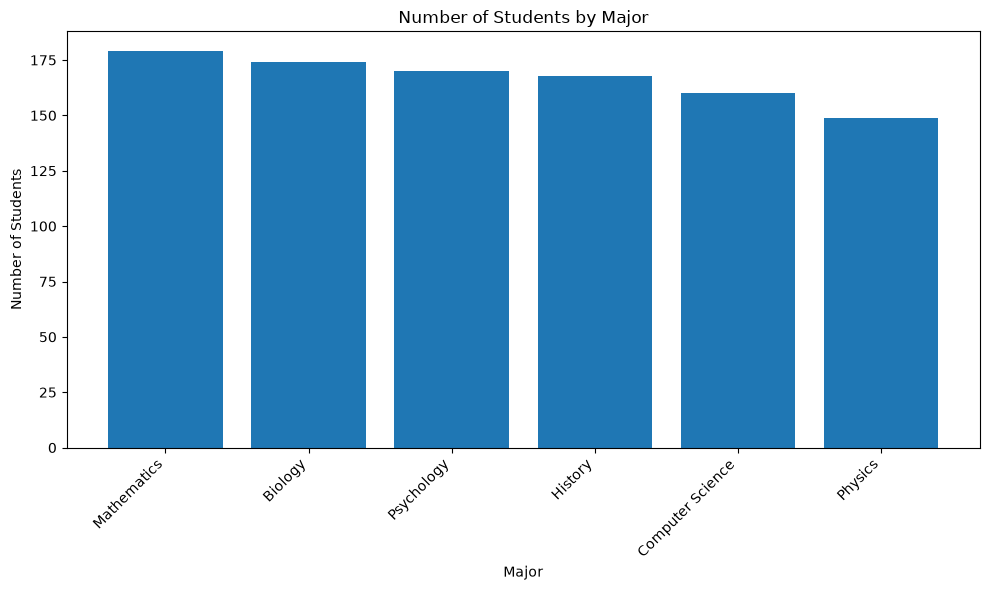

In [16]:
# رسم عدد الطلاب في كل تخصص

if 'Major' in df.columns:

    major_counts = df['Major'].value_counts()

    plt.figure(figsize=(10, 6))

    plt.bar(
        major_counts.index,
        major_counts.values
    )

    plt.title('Number of Students by Major')
    plt.xlabel('Major')
    plt.ylabel('Number of Students')

    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

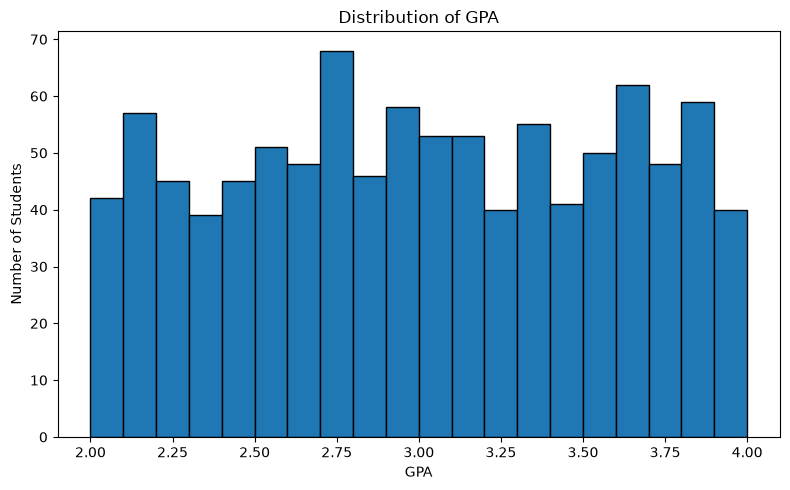

In [17]:
# عرض توزيع GPA

plt.figure(figsize=(8, 5))

plt.hist(
    df['GPA'],
    bins=20,
    edgecolor='black'
)

plt.title('Distribution of GPA')
plt.xlabel('GPA')
plt.ylabel('Number of Students')

plt.tight_layout()
plt.show()

In [18]:
# عرض الإحصائيات الوصفية لمؤشر النجاح الدراسي GPA

df['GPA'].describe()

count    1000.000000
mean        3.008000
std         0.569455
min         2.000000
25%         2.537500
50%         3.000000
75%         3.512500
max         4.000000
Name: GPA, dtype: float64

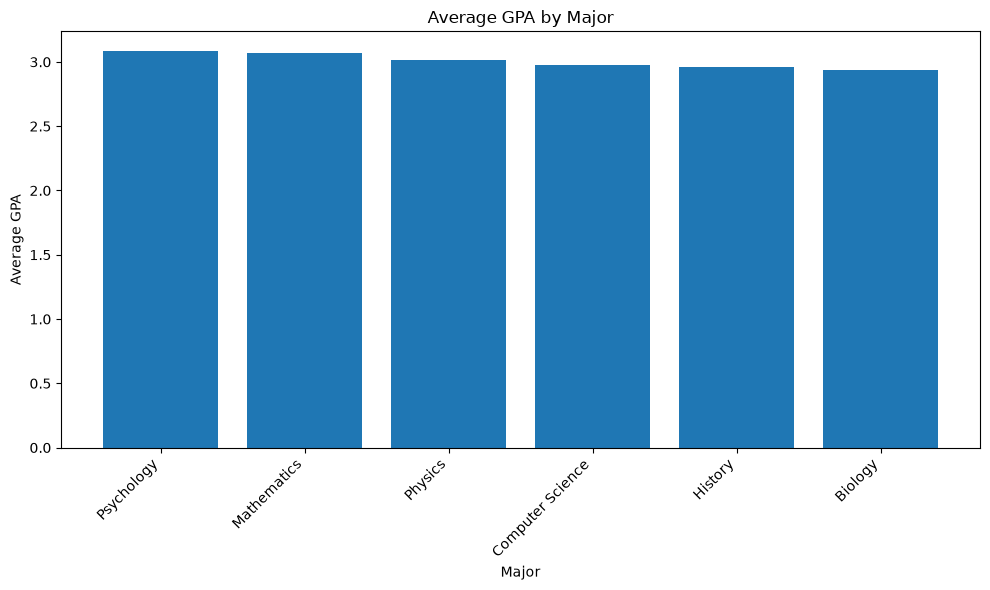

In [19]:
# مقارنة متوسط GPA بين التخصصات

if 'Major' in df.columns:

    major_gpa = (
        df.groupby('Major')['GPA']
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 6))

    plt.bar(
        major_gpa.index,
        major_gpa.values
    )

    plt.title('Average GPA by Major')
    plt.xlabel('Major')
    plt.ylabel('Average GPA')

    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

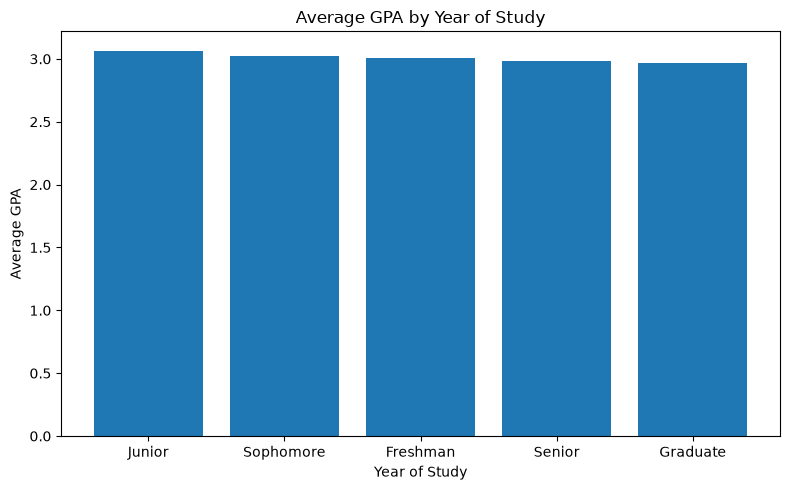

In [20]:
# مقارنة متوسط GPA حسب السنة الدراسية

if 'YearOfStudy' in df.columns:

    year_gpa = (
        df.groupby('YearOfStudy')['GPA']
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(8, 5))

    plt.bar(
        year_gpa.index,
        year_gpa.values
    )

    plt.title('Average GPA by Year of Study')
    plt.xlabel('Year of Study')
    plt.ylabel('Average GPA')

    plt.tight_layout()
    plt.show()

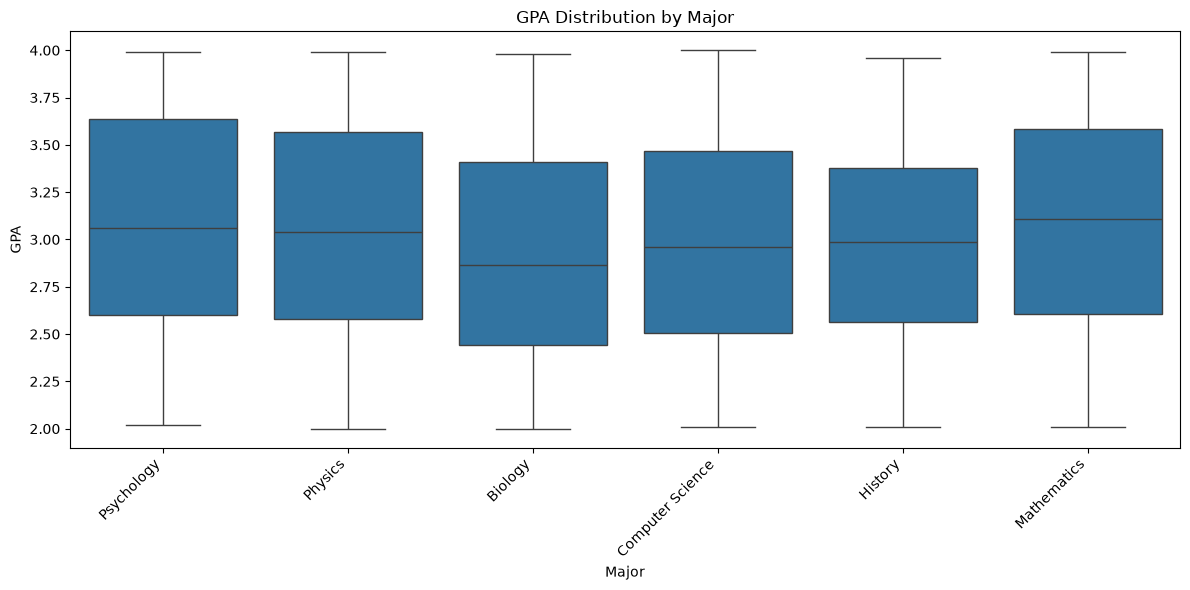

In [21]:
# عرض توزيع GPA حسب التخصص

if 'Major' in df.columns:

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=df,
        x='Major',
        y='GPA'
    )

    plt.title('GPA Distribution by Major')
    plt.xlabel('Major')
    plt.ylabel('GPA')

    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

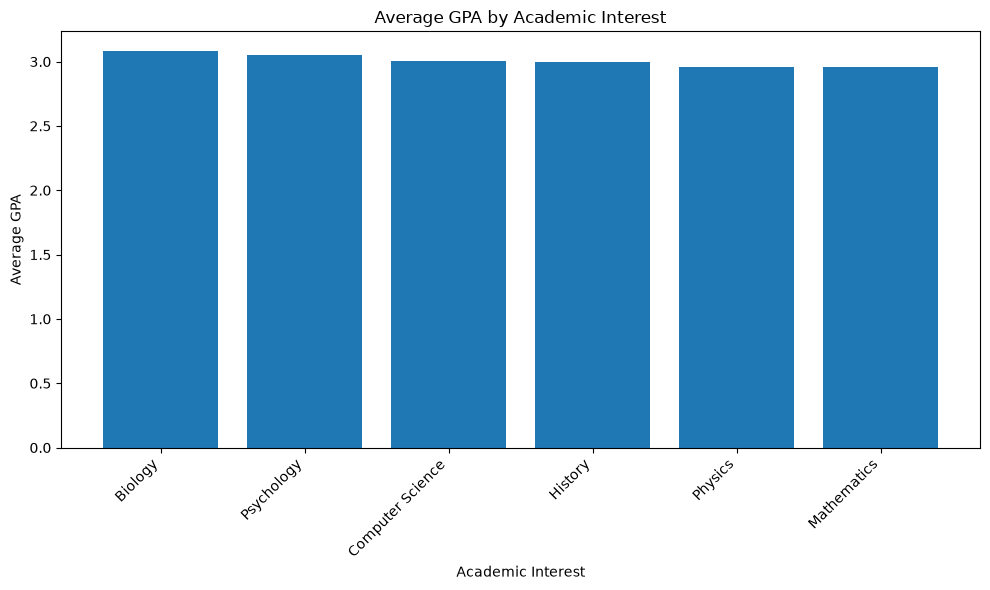

In [22]:
# عرض متوسط GPA حسب الاهتمام الأكاديمي

if 'AcademicInterest' in df.columns:

    interest_gpa = (
        df.groupby('AcademicInterest')['GPA']
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 6))

    plt.bar(
        interest_gpa.index,
        interest_gpa.values
    )

    plt.title('Average GPA by Academic Interest')
    plt.xlabel('Academic Interest')
    plt.ylabel('Average GPA')

    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

In [23]:
# معرفة الارتباط بين الأعمدة الرقمية

numeric_columns = df.select_dtypes(include=np.number).columns

correlation = df[numeric_columns].corr()

correlation

,GPA
GPA,1.0


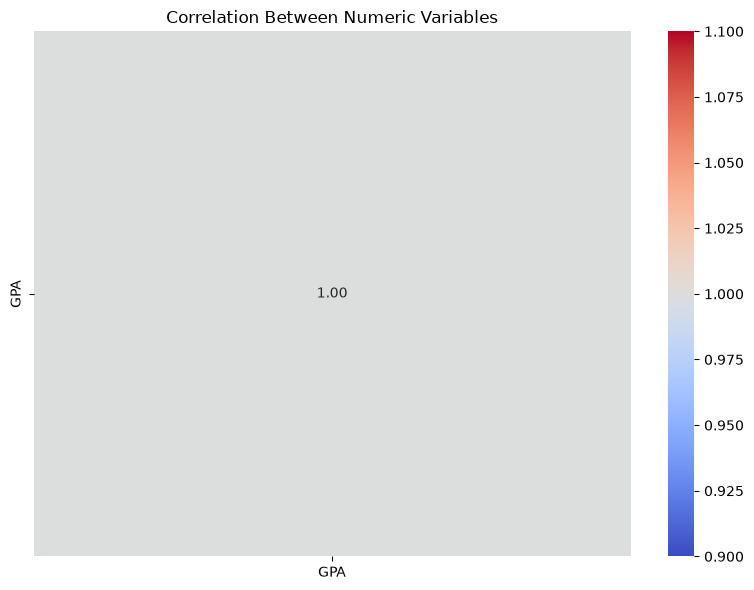

In [24]:
# رسم خريطة الارتباط للأعمدة الرقمية

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Numeric Variables')

plt.tight_layout()
plt.show()

In [25]:
# حساب عدد القيم الشاذة في GPA باستخدام IQR

Q1 = df['GPA'].quantile(0.25)
Q3 = df['GPA'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['GPA'] < lower_bound) |
    (df['GPA'] > upper_bound)
]

print("GPA outliers:", len(outliers))

GPA outliers: 0


<div dir="rtl" style="text-align: right;">

## تجهيز البيانات للنمذجة (Data Preparation for Modeling)

في هذه المرحلة يتم تحديد المتغيرات المستقلة **Features** التي تصف الطالب، وتحديد المتغير الهدف **Target** وهو GPA. بعد ذلك يتم تقسيم البيانات إلى بيانات تدريب وبيانات اختبار حتى يتم تدريب النموذج على جزء من البيانات ثم تقييمه على بيانات لم يسبق له رؤيتها.

</div>

In [26]:
# عرض أسماء الأعمدة النهائية
df.columns.tolist()

['AcademicInterest',
 'ExtracurricularActivities',
 'Skills',
 'Location',
 'YearOfStudy',
 'Major',
 'GPA',
 'Languages',
 'ClubMemberships',
 'ResearchInterests']

In [27]:
# تحديد المدخلات والهدف

target_column = 'GPA'

feature_columns = [
    column for column in df.columns
    if column != target_column
]

X = df[feature_columns]

y = df[target_column]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(feature_columns)

Features shape: (1000, 9)
Target shape: (1000,)

Feature columns:
['AcademicInterest', 'ExtracurricularActivities', 'Skills', 'Location', 'YearOfStudy', 'Major', 'Languages', 'ClubMemberships', 'ResearchInterests']


In [28]:
from sklearn.model_selection import train_test_split

# تقسيم البيانات إلى تدريب واختبار

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (800, 9)
Testing Features: (200, 9)
Training Target: (800,)
Testing Target: (200,)


In [29]:
# تحديد الأعمدة الرقمية والفئوية

numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numeric Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numeric Features: []
Categorical Features: ['AcademicInterest', 'ExtracurricularActivities', 'Skills', 'Location', 'YearOfStudy', 'Major', 'Languages', 'ClubMemberships', 'ResearchInterests']


<div dir="rtl" style="text-align: right;">

## تدريب نماذج الذكاء الاصطناعي ومقارنتها (Model Training & Comparison)

في هذه المرحلة يتم تدريب أكثر من نموذج لتوقع قيمة GPA، ثم تتم مقارنة النماذج باستخدام مقاييس مثل **MAE** و **RMSE** و **R² Score**. بعد المقارنة يتم اختيار النموذج الأفضل لاستخدامه في خدمة التنبؤ.

</div>

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# تجهيز البيانات الفئوية قبل تدريب النماذج

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(
                handle_unknown='ignore'
            ),
            categorical_features
        )
    ],
    remainder='passthrough'
)

print("Data preprocessor created successfully!")

Data preprocessor created successfully!


In [31]:
from sklearn.ensemble import RandomForestRegressor

# إنشاء نموذج Random Forest

random_forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# تدريب النموذج

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [33]:
from sklearn.ensemble import GradientBoostingRegressor

# إنشاء نموذج Gradient Boosting

gradient_boosting_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            GradientBoostingRegressor(
                random_state=42
            )
        )
    ]
)

# تدريب النموذج

gradient_boosting_model.fit(
    X_train,
    y_train
)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [34]:
# إنشاء تنبؤات نموذج Random Forest

rf_predictions = random_forest_model.predict(X_test)

print("Random Forest predictions completed successfully!")

Random Forest predictions completed successfully!


In [35]:
# إنشاء تنبؤات نموذج Gradient Boosting

gb_predictions = gradient_boosting_model.predict(X_test)

print("Gradient Boosting predictions completed successfully!")

Gradient Boosting predictions completed successfully!


In [36]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# حساب نتائج نموذج Random Forest

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = mean_squared_error(
    y_test,
    rf_predictions
) ** 0.5

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R²:", rf_r2)

Random Forest MAE: 0.48927075
Random Forest RMSE: 0.5717891193329057
Random Forest R²: -0.04527065429341959


In [37]:
# حساب نتائج نموذج Gradient Boosting

gb_mae = mean_absolute_error(
    y_test,
    gb_predictions
)

gb_rmse = mean_squared_error(
    y_test,
    gb_predictions
) ** 0.5

gb_r2 = r2_score(
    y_test,
    gb_predictions
)

print("Gradient Boosting MAE:", gb_mae)
print("Gradient Boosting RMSE:", gb_rmse)
print("Gradient Boosting R²:", gb_r2)

Gradient Boosting MAE: 0.4904289093619778
Gradient Boosting RMSE: 0.5613043551455765
Gradient Boosting R²: -0.007288342912953327


In [38]:
# مقارنة النماذج

comparison_results = pd.DataFrame({
    'Model': [
        'Random Forest',
        'Gradient Boosting'
    ],
    'MAE': [
        rf_mae,
        gb_mae
    ],
    'RMSE': [
        rf_rmse,
        gb_rmse
    ],
    'R2 Score': [
        rf_r2,
        gb_r2
    ]
})

comparison_results = comparison_results.sort_values(
    by='R2 Score',
    ascending=False
)

comparison_results

,Model,MAE,RMSE,R2 Score
1,Gradient Boosting,0.490429,0.561304,-0.007288
0,Random Forest,0.489271,0.571789,-0.045271


In [39]:
# اختيار النموذج الأفضل

if rf_r2 >= gb_r2:

    model = random_forest_model
    best_model_name = "Random Forest"
    y_pred = rf_predictions

else:

    model = gradient_boosting_model
    best_model_name = "Gradient Boosting"
    y_pred = gb_predictions

print("Best Model:", best_model_name)

Best Model: Gradient Boosting


<div dir="rtl" style="text-align: right;">

## تقييم النموذج الأفضل (Model Evaluation)

بعد اختيار النموذج الأفضل، يتم تقييم أدائه بشكل أوضح من خلال مقارنة القيم الحقيقية لـ GPA مع القيم التي توقعها النموذج، بالإضافة إلى قياس نسبة الخطأ ومقدار قدرة النموذج على تفسير التغير في مستوى الأداء الدراسي.

</div>

In [40]:
# حساب المقاييس النهائية للنموذج الأفضل

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = mean_squared_error(
    y_test,
    y_pred
) ** 0.5

r2 = r2_score(
    y_test,
    y_pred
)

print("Best Model:", best_model_name)
print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)
print("R² Score:", r2)

Best Model: Gradient Boosting
Mean Absolute Error: 0.4904289093619778
Root Mean Squared Error: 0.5613043551455765
R² Score: -0.007288342912953327


In [41]:
# مقارنة القيم الحقيقية بالقيم المتوقعة

evaluation_results = pd.DataFrame({
    'Actual GPA': y_test.values,
    'Predicted GPA': y_pred
})

evaluation_results.head(10)

,Actual GPA,Predicted GPA
0,3.57,2.986635
1,3.67,3.153487
2,3.71,3.010863
3,2.19,2.986635
4,2.73,2.832112
5,2.75,2.986635
6,3.75,2.986635
7,2.71,2.960716
8,2.75,2.946562
9,2.99,2.917023


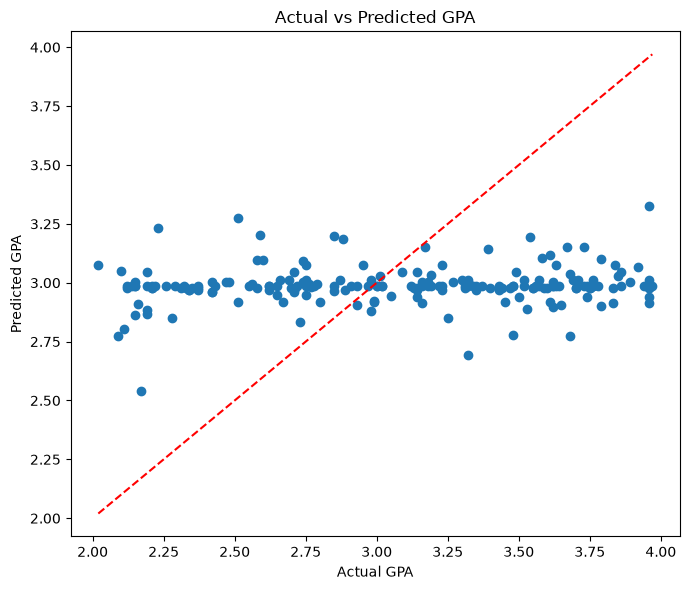

In [42]:
# رسم القيم الحقيقية مقابل القيم المتوقعة

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred
)

plt.xlabel('Actual GPA')
plt.ylabel('Predicted GPA')
plt.title('Actual vs Predicted GPA')

minimum = min(
    y_test.min(),
    y_pred.min()
)

maximum = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--'
)

plt.tight_layout()
plt.show()

In [43]:
# حساب متوسط نسبة الخطأ بالنسبة المئوية

non_zero_actual = y_test != 0

percentage_error = (
    np.abs(
        (
            y_test[non_zero_actual] -
            y_pred[non_zero_actual]
        ) /
        y_test[non_zero_actual]
    )
    * 100
)

print(
    "Average Percentage Error:",
    percentage_error.mean()
)

Average Percentage Error: 16.605335960161884


<div dir="rtl" style="text-align: right;">

## التنبؤ على بيانات جديدة (Making Predictions)

في هذه المرحلة يتم استخدام النموذج الأفضل بعد تدريبه للتنبؤ بقيمة GPA المتوقعة لطالب جديد. يتم إدخال بيانات الطالب ثم يقوم النموذج بتحليل خصائصه وإرجاع مستوى الأداء الدراسي المتوقع.

</div>

In [44]:
# عرض مثال من القيم الموجودة في البيانات

for column in categorical_features:

    print(
        f"{column}:",
        df[column].dropna().unique()[:10]
    )

AcademicInterest: <StringArray>
[      'Psychology',          'History', 'Computer Science',
          'Biology',      'Mathematics',          'Physics']
Length: 6, dtype: str
ExtracurricularActivities: <StringArray>
[    'Debate Club', 'Volunteer Group',     'Sports Team',        'Art Club',
     'Coding Club',      'Music Club']
Length: 6, dtype: str
Skills: <StringArray>
[                                                                   'Problem Solving',
           'Leadership, Problem Solving, Public Speaking, Data Analysis, Programming',
              'Data Analysis, Leadership, Public Speaking, Artistic, Problem Solving',
                                    'Public Speaking, Data Analysis, Problem Solving',
                                                                      'Data Analysis',
                                                          'Public Speaking, Artistic',
                          'Public Speaking, Problem Solving, Data Analysis, Artistic',
              

In [45]:
# إنشاء بيانات طالب جديدة للتجربة

# تم أخذ نموذج بيانات صالح من نفس مجموعة البيانات
# ويمكن تعديل القيم لاحقًا عند بناء واجهة الويب

new_student = X.iloc[[0]].copy()

new_student

,AcademicInterest,ExtracurricularActivities,Skills,Location,YearOfStudy,Major,Languages,ClubMemberships,ResearchInterests
0,Psychology,Debate Club,Problem Solving,New York,Freshman,Psychology,"Chinese, Japanese, Spanish, German, French","Music Club, Art Club, Sports Team, Debate Club...",Biomedical Engineering


In [46]:
# التنبؤ بقيمة GPA للطالب الجديد

predicted_gpa = model.predict(
    new_student
)[0]

print(
    "Predicted GPA:",
    round(predicted_gpa, 2)
)

Predicted GPA: 2.99


In [47]:
# تحويل قيمة GPA المتوقعة إلى مستوى نجاح دراسي

def get_success_level(gpa):

    if gpa >= 3.5:
        return "Excellent"

    elif gpa >= 3.0:
        return "Very Good"

    elif gpa >= 2.5:
        return "Good"

    elif gpa >= 2.0:
        return "Average"

    else:
        return "Needs Improvement"

success_level = get_success_level(
    predicted_gpa
)

print(
    "Predicted Study Success Level:",
    success_level
)

Predicted Study Success Level: Good


<div dir="rtl" style="text-align: right;">

## حفظ النموذج (Model Saving)

في هذه المرحلة يتم حفظ النموذج الأفضل بعد الانتهاء من تدريبه ومقارنته وتقييمه، بحيث يمكن استخدامه لاحقًا في واجهة الويب للتنبؤ بمستوى النجاح الدراسي دون الحاجة إلى إعادة تدريب النموذج.

</div>

In [48]:
import joblib

# حفظ النموذج الأفضل

model_path = "../models/study_success_model.pkl"

joblib.dump(
    model,
    model_path
)

print("Model saved successfully!")

Model saved successfully!
